# B9. Hiệu chỉnh xác suất

Đưa đầu ra của ba mô hình B8 về đúng thang xác suất mà QĐ-26 khoản 3 Điều 2 yêu cầu: "điểm 12% có nghĩa là trong 100 hồ sơ có điểm khoảng 12%, dự kiến khoảng 12 hồ sơ gặp khó khăn trả nợ".
Chỉ dùng dự đoán ngoài fold của tập train (`ml/data/oof.parquet`, B8): mỗi hồ sơ được dự đoán bởi mô hình chưa học hồ sơ đó. Tập test chưa được chạm.
Đầu ra: `ml/data/hieu_chinh.json` (cách hiệu chỉnh và tham số của từng mô hình, B10, B11, B13 dùng), `ml/data/oof_hieu_chinh.parquet` (dự đoán ngoài fold đã hiệu chỉnh theo kiểu chéo, B10 chọn ngưỡng).

## 0. Nguồn đã tra và cách áp dụng

| Nguồn | Nội dung | Áp dụng |
|---|---|---|
| scikit-learn 1.9, *Probability calibration* (User Guide 1.16); tài liệu `CalibratedClassifierCV`, `calibration_curve` | Bộ hiệu chỉnh phải học trên dữ liệu độc lập với dữ liệu huấn luyện mô hình. Với `ensemble=False`, dự đoán ngoài fold (`cross_val_predict`) dùng để học bộ hiệu chỉnh, mô hình cuối học trên toàn bộ dữ liệu. Sigmoid hợp với ít dữ liệu; isotonic sửa được mọi méo đơn điệu, cần nhiều dữ liệu (> ~1.000 mẫu), tạo giá trị trùng nên AUC có thể đổi. Brier, log loss là quy tắc chấm điểm chặt (strictly proper) nhưng trộn cả hiệu chỉnh lẫn phân biệt, nên phải xem kèm đường cong. Rừng ngẫu nhiên khó cho xác suất gần 0 và 1 | Học bộ hiệu chỉnh trên `oof.parquet`, đúng kiểu `ensemble=False`; so 3 cách: không hiệu chỉnh, sigmoid, isotonic; Brier + log loss + đường cong 20 nhóm `strategy="quantile"` (xác suất dồn dưới 20% nên nhóm đều độ rộng sẽ gần như rỗng ở phía trên) |
| Platt (1999), *Probabilistic Outputs for Support Vector Machines*; Cox (1958), *Two further applications of a model for binary regression*, Biometrika 45 | Hiệu chỉnh sigmoid: hồi quy logistic một biến trên điểm của mô hình. Cox: hồi quy nhãn trên log-odds dự đoán; hệ số góc 1 và hệ số chặn 0 là khớp | Sigmoid học trên **log-odds** của xác suất (thay vì xác suất thô như bản gốc của Platt) để hệ số góc của Cox đọc được trực tiếp; bỏ bước làm mượt nhãn của Platt vì với khoảng 196.800 hồ sơ mỗi lần học nó không đổi kết quả |
| Zadrozny, Elkan (2002), *Transforming Classifier Scores into Accurate Multiclass Probability Estimates*, KDD | Hồi quy isotonic: hàm bậc thang không giảm khớp nhãn tốt nhất theo bình phương sai số | Cách thứ ba, `IsotonicRegression(out_of_bounds="clip")` |
| Niculescu-Mizil, Caruana (2005), *Predicting Good Probabilities with Supervised Learning*, ICML | Cây tăng cường đẩy xác suất xa 0 và 1 (méo hình chữ S); rừng ngẫu nhiên cần hiệu chỉnh; sau hiệu chỉnh, cây tăng cường và rừng ngẫu nhiên cho xác suất tốt nhất; isotonic hơn Platt khi đủ dữ liệu | Hiệu chỉnh cả ba mô hình rồi so; không giả định trước mô hình nào đã khớp |
| Van Calster và cộng sự (2019), *Calibration: the Achilles heel of predictive analytics*, BMC Medicine 17:230 | Các mức kiểm tra: khớp trung bình (calibration-in-the-large), hệ số góc hiệu chỉnh, đường cong hiệu chỉnh; hệ số góc < 1 là dự đoán quá cực đoan, > 1 là quá dè dặt | Báo cáo chênh trung bình dự đoán − tỷ lệ thật, hệ số góc Cox và đường cong |
| Brier (1950), *Verification of forecasts expressed in terms of probability*, Monthly Weather Review 78 | Brier = trung bình (xác suất − nhãn)² | Metric chọn cách hiệu chỉnh (đúng quy trình B9) |
| Saerens, Latinne, Decaestecker (2002), *Adjusting the Outputs of a Classifier to New a Priori Probabilities*, Neural Computation 14 | Mô hình học trên tỷ lệ lớp khác thực tế cho xác suất lệch, phải chỉnh lại | Giải thích vì sao RF trọng số `balanced` (B8) lệch; không dùng công thức chỉnh tiên nghiệm của họ vì RF không phải mô hình xác suất, dùng sigmoid/isotonic học từ dữ liệu |
| QĐ-26 Điều 2, 3, 7 (corpus AT Credit) | Điểm đã hiệu chỉnh; ba dải < 5%, 5% đến < 15%, ≥ 15% theo điểm làm tròn 1 chữ số; giám sát tỷ lệ thật của từng dải so với khoảng điểm của dải | Kiểm tra tỷ lệ thật của từng dải trên dự đoán ngoài fold đã hiệu chỉnh |

Không áp dụng: kiểm định Hosmer–Lemeshow (với ~49.000 hồ sơ mỗi fold, sai lệch nhỏ không đáng kể về thực tế cũng thành "có ý nghĩa"); ECE (phụ thuộc cách chia nhóm, đường cong đã thể hiện cùng thông tin);
bản `ensemble=True` của scikit-learn (mô hình cuối của B11 học trên toàn bộ train như B8 đã chốt số cây).

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
FIG_DIR = ROOT / "ml" / "hinh"
INK, MUTED, BLUE, ORANGE, GRID = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834", "#e4e3df"
MO_HINH = ["LR", "RF", "LGBM"]
CACH = ["khong", "sigmoid", "isotonic"]
pd.set_option("display.float_format", lambda v: f"{v:,.5f}")
warnings.filterwarnings("ignore", category=FutureWarning)

d = pd.read_parquet(ROOT / "ml" / "data" / "oof.parquet")
y, fold = d.TARGET.to_numpy(), d.fold.to_numpy()
print(f"Dự đoán ngoài fold: {len(d):,} hồ sơ train, TARGET=1 {y.mean():.4%}, fold {np.bincount(fold).tolist()}")

Dự đoán ngoài fold: 246,008 hồ sơ train, TARGET=1 8.0729%, fold [49202, 49202, 49202, 49201, 49201]


## 1. Cách làm và luật chọn

**Ba cách**, từ đơn giản đến phức tạp:
- `khong`: giữ nguyên xác suất của mô hình.
- `sigmoid`: q = 1 / (1 + e^−(a · logit(p) + b)), hai tham số a, b học bằng hồi quy logistic không điều chuẩn.
- `isotonic`: hàm bậc thang không giảm, học bằng hồi quy isotonic; ngoài khoảng đã học thì giữ giá trị ở đầu mút.

**Đánh giá chéo, không để bộ hiệu chỉnh tự chấm mình.** Dự đoán ngoài fold đã độc lập với mô hình, nhưng nếu học bộ hiệu chỉnh và chấm nó trên cùng các dự đoán đó thì isotonic (rất nhiều bậc) được lợi.
Vì vậy với mỗi fold k: học bộ hiệu chỉnh trên dự đoán ngoài fold của 4 fold còn lại, áp lên fold k, chấm Brier trên fold k. Năm fold cho năm giá trị Brier mỗi cách.

**Luật chọn**, đúng luật của notebook 07: cách phức tạp hơn chỉ được giữ nếu Brier thấp hơn cách đang giữ ở **cả 5 fold** (nếu không có tác dụng thật thì xác suất này là 1/2⁵ ≈ 3%).
Bắt đầu từ `khong`; so `sigmoid` với `khong`; rồi so `isotonic` với cách đang giữ.

**Bộ hiệu chỉnh cuối** của mỗi mô hình học trên toàn bộ dự đoán ngoài fold (246.008 hồ sơ), như `CalibratedClassifierCV(ensemble=False)`. B11 áp nó lên dự đoán của mô hình cuối (học trên toàn bộ train) cho tập test.

In [2]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def hoc(cach, p, nhan):
    if cach == "khong":
        return {"cach": "khong"}
    if cach == "sigmoid":
        m = LogisticRegression(C=np.inf).fit(logit(p)[:, None], nhan)
        return {"cach": "sigmoid", "a": float(m.coef_[0, 0]), "b": float(m.intercept_[0])}
    m = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p, nhan)
    return {"cach": "isotonic", "x": m.X_thresholds_.tolist(), "y": m.y_thresholds_.tolist()}


def ap(hc, p):
    if hc["cach"] == "khong":
        return p
    if hc["cach"] == "sigmoid":
        return 1 / (1 + np.exp(-(hc["a"] * logit(p) + hc["b"])))
    return np.interp(p, hc["x"], hc["y"])


def cheo(cach, p):
    q = np.empty(len(p))
    for k in range(5):
        q[fold == k] = ap(hoc(cach, p[fold != k], y[fold != k]), p[fold == k])
    return q


def do_khop(q, nhan):
    # hệ số góc và hệ số chặn của Cox: hồi quy nhãn trên log-odds dự đoán
    m = LogisticRegression(C=np.inf).fit(logit(q)[:, None], nhan)
    return {"TB dự đoán": q.mean(), "tỷ lệ thật": nhan.mean(), "chênh TB": q.mean() - nhan.mean(), "hệ số góc": m.coef_[0, 0], "hệ số chặn": m.intercept_[0]}


# kiểm tra: ap() kiểu np.interp cho đúng kết quả của IsotonicRegression.predict
p0 = d.LR.to_numpy()
m0 = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p0[fold != 0], y[fold != 0])
print("isotonic np.interp == predict:", np.allclose(ap(hoc("isotonic", p0[fold != 0], y[fold != 0]), p0[fold == 0]), m0.predict(p0[fold == 0])))

isotonic np.interp == predict: True


## 2. Trước hiệu chỉnh

In [3]:
truoc = pd.DataFrame({m: {**do_khop(d[m].to_numpy(), y), "Brier": brier_score_loss(y, d[m]), "log loss": log_loss(y, d[m])} for m in MO_HINH}).T
truoc

,TB dự đoán,tỷ lệ thật,chênh TB,hệ số góc,hệ số chặn,Brier,log loss
LR,0.08074,0.08073,0.00001,0.99499,-0.01068,0.06741,0.24398
RF,0.30836,0.08073,0.22763,1.34471,-1.64598,0.12543,0.41471
LGBM,0.07927,0.08073,-0.00146,1.00192,0.02632,0.06604,0.23754


In [4]:
# thập phân vị theo xác suất của từng mô hình: xác suất trung bình so với tỷ lệ thật
tp = {}
for m in MO_HINH:
    g = pd.DataFrame({"p": d[m], "y": y}).groupby(pd.qcut(d[m], 10, labels=range(1, 11)), observed=True).mean()
    tp[(m, "dự đoán")], tp[(m, "thật")] = g.p, g.y
pd.DataFrame(tp).style.format("{:.1%}")

## 3. So ba cách hiệu chỉnh bằng đánh giá chéo

In [5]:
q_cheo = {(m, c): cheo(c, d[m].to_numpy()) for m in MO_HINH for c in CACH}
brier = pd.DataFrame({(m, c): [brier_score_loss(y[fold == k], q[fold == k]) for k in range(5)] for (m, c), q in q_cheo.items()})
brier.index.name = "fold"
brier

LR                       RF                     LGBM          \
       khong sigmoid isotonic   khong sigmoid isotonic   khong sigmoid   
fold                                                                     
0    0.06756 0.06756  0.06753 0.12559 0.06749  0.06750 0.06623 0.06623   
1    0.06743 0.06743  0.06735 0.12564 0.06734  0.06735 0.06608 0.06609   
2    0.06738 0.06738  0.06736 0.12593 0.06733  0.06734 0.06590 0.06590   
3    0.06731 0.06731  0.06730 0.12488 0.06725  0.06726 0.06591 0.06590   
4    0.06737 0.06737  0.06735 0.12509 0.06705  0.06708 0.06605 0.06605   

               
     isotonic  
fold           
0     0.06621  
1     0.06605  
2     0.06588  
3     0.06593  
4     0.06608

In [6]:
tong = pd.DataFrame({(m, c): {"Brier TB": brier[(m, c)].mean(), "log loss": log_loss(y, q),
                              "AUC TB 5 fold": np.mean([roc_auc_score(y[fold == k], q[fold == k]) for k in range(5)]),
                              **do_khop(q, y)} for (m, c), q in q_cheo.items()}).T
tong

Brier TB  log loss  AUC TB 5 fold  TB dự đoán  tỷ lệ thật  \
LR   khong      0.06741   0.24398        0.76621     0.08074     0.08073   
     sigmoid    0.06741   0.24398        0.76621     0.08072     0.08073   
     isotonic   0.06738   0.24413        0.76596     0.08074     0.08073   
RF   khong      0.12543   0.41471        0.76952     0.30836     0.08073   
     sigmoid    0.06729   0.24307        0.76952     0.08069     0.08073   
     isotonic   0.06731   0.24325        0.76940     0.08073     0.08073   
LGBM khong      0.06604   0.23754        0.78577     0.07927     0.08073   
     sigmoid    0.06604   0.23753        0.78577     0.08073     0.08073   
     isotonic   0.06603   0.23791        0.78561     0.08074     0.08073   

               chênh TB  hệ số góc  hệ số chặn  
LR   khong      0.00001    0.99499    -0.01068  
     sigmoid   -0.00001    0.99998    -0.00004  
     isotonic   0.00001    0.99314    -0.01437  
RF   khong      0.22763    1.34471    -1.64598  
     sigmoid   -0.00003    1.00088     0.00224  
     isotonic  -0.00000    0.99339    -0.01361  
LGBM khong     -0.00146    1.00192     0.02632  
     sigmoid    0.00000    0.99921    -0.00162  
     isotonic   0.00001    0.99222    -0.01570

In [7]:
chon = {}
for m in MO_HINH:
    giu = "khong"
    for moi in ["sigmoid", "isotonic"]:
        thang = int((brier[(m, moi)] < brier[(m, giu)]).sum())
        chenh = (brier[(m, moi)] - brier[(m, giu)]).to_numpy()
        print(f"{m:4s} {moi:8s} vs {giu:8s}: thấp hơn ở {thang}/5 fold, chênh Brier {chenh.min():+.6f} … {chenh.max():+.6f}")
        if thang == 5:
            giu = moi
    chon[m] = giu
print("Chọn:", chon)

LR   sigmoid  vs khong   : thấp hơn ở 4/5 fold, chênh Brier -0.000002 … +0.000001
LR   isotonic vs khong   : thấp hơn ở 5/5 fold, chênh Brier -0.000079 … -0.000011
RF   sigmoid  vs khong   : thấp hơn ở 5/5 fold, chênh Brier -0.058603 … -0.057622
RF   isotonic vs sigmoid : thấp hơn ở 0/5 fold, chênh Brier +0.000008 … +0.000023
LGBM sigmoid  vs khong   : thấp hơn ở 2/5 fold, chênh Brier -0.000009 … +0.000009
LGBM isotonic vs khong   : thấp hơn ở 3/5 fold, chênh Brier -0.000032 … +0.000025
Chọn: {'LR': 'isotonic', 'RF': 'sigmoid', 'LGBM': 'khong'}


## 4. Bộ hiệu chỉnh cuối và lưu

In [8]:
cuoi = {m: hoc(chon[m], d[m].to_numpy(), y) for m in MO_HINH}
for m, hc in cuoi.items():
    mo_ta = {"khong": "", "sigmoid": f"a = {hc.get('a', 0):.4f}, b = {hc.get('b', 0):.4f}", "isotonic": f"{len(hc.get('x', []))} điểm mốc"}[hc["cach"]]
    print(f"{m:4s} {hc['cach']:8s} {mo_ta}")
(ROOT / "ml" / "data" / "hieu_chinh.json").write_text(json.dumps(cuoi))

oof_hc = pd.DataFrame({"SK_ID_CURR": d.SK_ID_CURR, "fold": fold, "TARGET": y, **{m: q_cheo[(m, chon[m])] for m in MO_HINH}})
oof_hc.to_parquet(ROOT / "ml" / "data" / "oof_hieu_chinh.parquet", index=False)
print("Đã lưu hieu_chinh.json, oof_hieu_chinh.parquet")

LR   isotonic 193 điểm mốc
RF   sigmoid  a = 1.3447, b = -1.6460
LGBM khong    
Đã lưu hieu_chinh.json, oof_hieu_chinh.parquet


## 5. Đường cong hiệu chỉnh

20 nhóm cùng số hồ sơ (~12.300 hồ sơ mỗi nhóm) theo xác suất; trục ngang: xác suất dự đoán trung bình của nhóm, trục dọc: tỷ lệ TARGET = 1 thật. Nằm trên đường chéo là khớp.
"Sau" là dự đoán ngoài fold đã hiệu chỉnh theo kiểu chéo, bằng cách đã chọn ở mục 3.

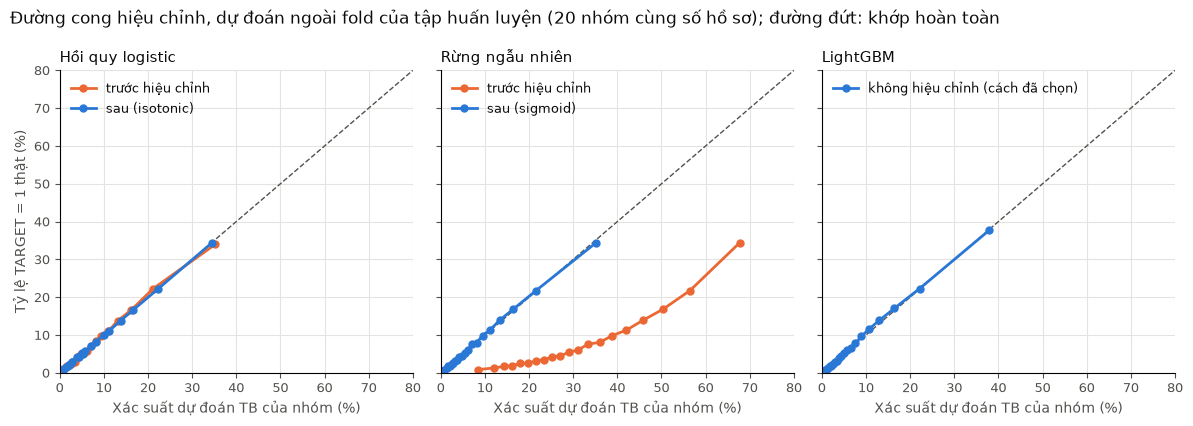

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4.3), sharey=True)
ten = {"LR": "Hồi quy logistic", "RF": "Rừng ngẫu nhiên", "LGBM": "LightGBM"}
ten_cach = {"khong": "", "sigmoid": "sigmoid", "isotonic": "isotonic"}
for p, m in zip(ax, MO_HINH):
    p.plot([0, 80], [0, 80], color=MUTED, lw=1, ls="--")
    duong = [(d[m].to_numpy(), ORANGE, "trước hiệu chỉnh"), (q_cheo[(m, chon[m])], BLUE, f"sau ({ten_cach[chon[m]]})")]
    if chon[m] == "khong":
        duong = [(d[m].to_numpy(), BLUE, "không hiệu chỉnh (cách đã chọn)")]
    for q, mau, nhan in duong:
        thuc, du = calibration_curve(y, q, n_bins=20, strategy="quantile")
        p.plot(du * 100, thuc * 100, color=mau, lw=2, marker="o", ms=5, label=nhan)
    p.set_xlim(0, 80)
    p.set_ylim(0, 80)
    p.set_title(ten[m], color=INK, fontsize=11, loc="left")
    p.set_xlabel("Xác suất dự đoán TB của nhóm (%)", color=MUTED)
    p.grid(color=GRID, lw=0.8)
    p.set_axisbelow(True)
    p.tick_params(colors=MUTED, labelsize=9)
    p.spines[["top", "right"]].set_visible(False)
    p.legend(frameon=False, fontsize=9, loc="upper left", labelcolor=INK)
ax[0].set_ylabel("Tỷ lệ TARGET = 1 thật (%)", color=MUTED)
fig.suptitle("Đường cong hiệu chỉnh, dự đoán ngoài fold của tập huấn luyện (20 nhóm cùng số hồ sơ); đường đứt: khớp hoàn toàn",
             color=INK, fontsize=12, x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "ml_hieu_chinh.png", dpi=150)

## 6. Ba dải rủi ro của QĐ-26

Điểm làm tròn 1 chữ số thập phân (theo %) rồi xếp dải (khoản 2 Điều 3). QĐ-26 điểm b khoản 1 và khoản 3 Điều 7 coi mô hình cần đánh giá lại khi tỷ lệ thật của một dải nằm ngoài khoảng điểm của dải đó.

In [10]:
def dai(q):
    diem = np.round(q * 100, 1)
    return np.select([diem < 5, diem < 15], ["thấp (< 5%)", "trung bình (5% – < 15%)"], "cao (≥ 15%)")


KHOANG = {"thấp (< 5%)": (0, 0.05), "trung bình (5% – < 15%)": (0.05, 0.15), "cao (≥ 15%)": (0.15, 1)}
bang = []
for m in MO_HINH:
    q = q_cheo[(m, chon[m])]
    for ten_dai, g in pd.DataFrame({"q": q, "y": y, "dai": dai(q)}).groupby("dai"):
        lo, hi = KHOANG[ten_dai]
        bang.append({"mô hình": m, "dải": ten_dai, "tỷ lệ hồ sơ": len(g) / len(q), "điểm TB": g.q.mean(), "tỷ lệ thật": g.y.mean(),
                     "thật trong khoảng dải": lo <= g.y.mean() < hi})
pd.DataFrame(bang).set_index(["mô hình", "dải"]).loc[[(m, t) for m in MO_HINH for t in KHOANG]]

tỷ lệ hồ sơ  điểm TB  tỷ lệ thật  \
mô hình dải                                                         
LR      thấp (< 5%)                  0.46729  0.02579     0.02604   
        trung bình (5% – < 15%)      0.37976  0.08361     0.08345   
        cao (≥ 15%)                  0.15295  0.24148     0.24104   
RF      thấp (< 5%)                  0.48611  0.02664     0.02540   
        trung bình (5% – < 15%)      0.36754  0.08632     0.08819   
        cao (≥ 15%)                  0.14635  0.24612     0.24579   
LGBM    thấp (< 5%)                  0.52175  0.02545     0.02473   
        trung bình (5% – < 15%)      0.33479  0.08574     0.09056   
        cao (≥ 15%)                  0.14346  0.25991     0.26144   

                                 thật trong khoảng dải  
mô hình dải                                             
LR      thấp (< 5%)                               True  
        trung bình (5% – < 15%)                   True  
        cao (≥ 15%)                               True  
RF      thấp (< 5%)                               True  
        trung bình (5% – < 15%)                   True  
        cao (≥ 15%)                               True  
LGBM    thấp (< 5%)                               True  
        trung bình (5% – < 15%)                   True  
        cao (≥ 15%)                               True

## 7. Tóm tắt

- Cách hiệu chỉnh đã chọn, tham số: `ml/data/hieu_chinh.json` (`ap()` ở mục 1 là cách áp: sigmoid trên log-odds, isotonic bằng nội suy tuyến tính giữa các mốc, ngoài khoảng giữ đầu mút).
- Dự đoán ngoài fold đã hiệu chỉnh kiểu chéo: `ml/data/oof_hieu_chinh.parquet` (B10 chọn ngưỡng trên file này).
- SHAP (B12) tính trên mô hình chưa hiệu chỉnh, ở thang log-odds; không cộng ra xác suất đã hiệu chỉnh (QĐ-26 khoản 2 Điều 5).
- Giới hạn: bộ hiệu chỉnh học trên dự đoán của 5 mô hình fold (mỗi mô hình học 80% train) nhưng sẽ áp lên mô hình cuối học 100% train; độ khớp thật kiểm tra trên tập test ở B11.